# **Messages**

In [13]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [14]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini")

llm.invoke("hi").content

'Hello! How can I assist you today?'

In [15]:
llm.invoke("hi")


AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_e61d09ff08', 'id': 'chatcmpl-El8aIEKp9G2dT1XlpFnrTqk45X85u', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1e890-1e56-7e71-96b4-e460262ad6da-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [16]:
from langchain_core.messages import HumanMessage
llm.invoke([HumanMessage(content="how are you ..?")])

AIMessage(content="I'm just a program, so I don't have feelings, but I'm here and ready to help you! How can I assist you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 12, 'total_tokens': 39, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_eb86cfd659', 'id': 'chatcmpl-El8aJYR456QhciF1uEjgbm6B3uGHL', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1e890-2238-76f1-a4f1-18ba981a42a6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 12, 'output_tokens': 27, 'total_tokens': 39, 'input_token_details': {'audio': 0, 'ca

In [17]:
from typing import TypedDict,List

class grapha_schema(TypedDict):
    message_manul: List

In [22]:
from langchain_core.messages import AIMessage

def create_post(state: grapha_schema) -> grapha_schema:

    message_manul = state['message_manul']

    response_manul = llm.invoke(message_manul).content
    response_manul_ai = AIMessage(content=response_manul)
    state['message_manul'] =  message_manul + [response_manul_ai]

    return state


def fine_tune(state: grapha_schema) -> grapha_schema:
    message_manul = state['message_manul']

    response_manul = llm.invoke(message_manul).content
    response_manul_ai = AIMessage(content=response_manul)
    state['message_manul'] =  message_manul + [response_manul_ai]

    return state

In [23]:
from langgraph.graph import StateGraph, START,END

# graph 

graph = StateGraph(grapha_schema)

# adding nodes

graph.add_node("create_post",create_post)
graph.add_node("fine_tune",fine_tune)

# edges connect

graph.add_edge(START,"create_post")
graph.add_edge("create_post","fine_tune")
graph.add_edge("fine_tune",END)

message_graph = graph.compile()

In [24]:
from IPython.display import display, Image

Image(message_graph.get_graph().draw_mermaid_png)

print((message_graph.get_graph().draw_mermaid()))

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	create_post(create_post)
	fine_tune(fine_tune)
	__end__([<p>__end__</p>]):::last
	__start__ --> create_post;
	create_post --> fine_tune;
	fine_tune --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [25]:
from langchain_core.messages import HumanMessage
message_graph.invoke(
    {
        "message_manul":[HumanMessage(content="What is importance of python in ML in 2 lines")]
    }
)

{'message_manul': [HumanMessage(content='What is importance of python in ML in 2 lines', additional_kwargs={}, response_metadata={}),
  AIMessage(content='Python is a dominant programming language in machine learning due to its simplicity and readability, which facilitate rapid development and prototyping. Additionally, its vast ecosystem of libraries and frameworks, such as TensorFlow, PyTorch, and scikit-learn, provides powerful tools for building and deploying machine learning models efficiently.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
  AIMessage(content='Python is a dominant programming language in machine learning due to its simplicity and readability, which facilitate rapid development and prototyping. Additionally, its vast ecosystem of libraries and frameworks, such as TensorFlow, PyTorch, and scikit-learn, provides powerful tools for building and deploying machine learning models efficiently.', additional_kwargs={}, response_metada

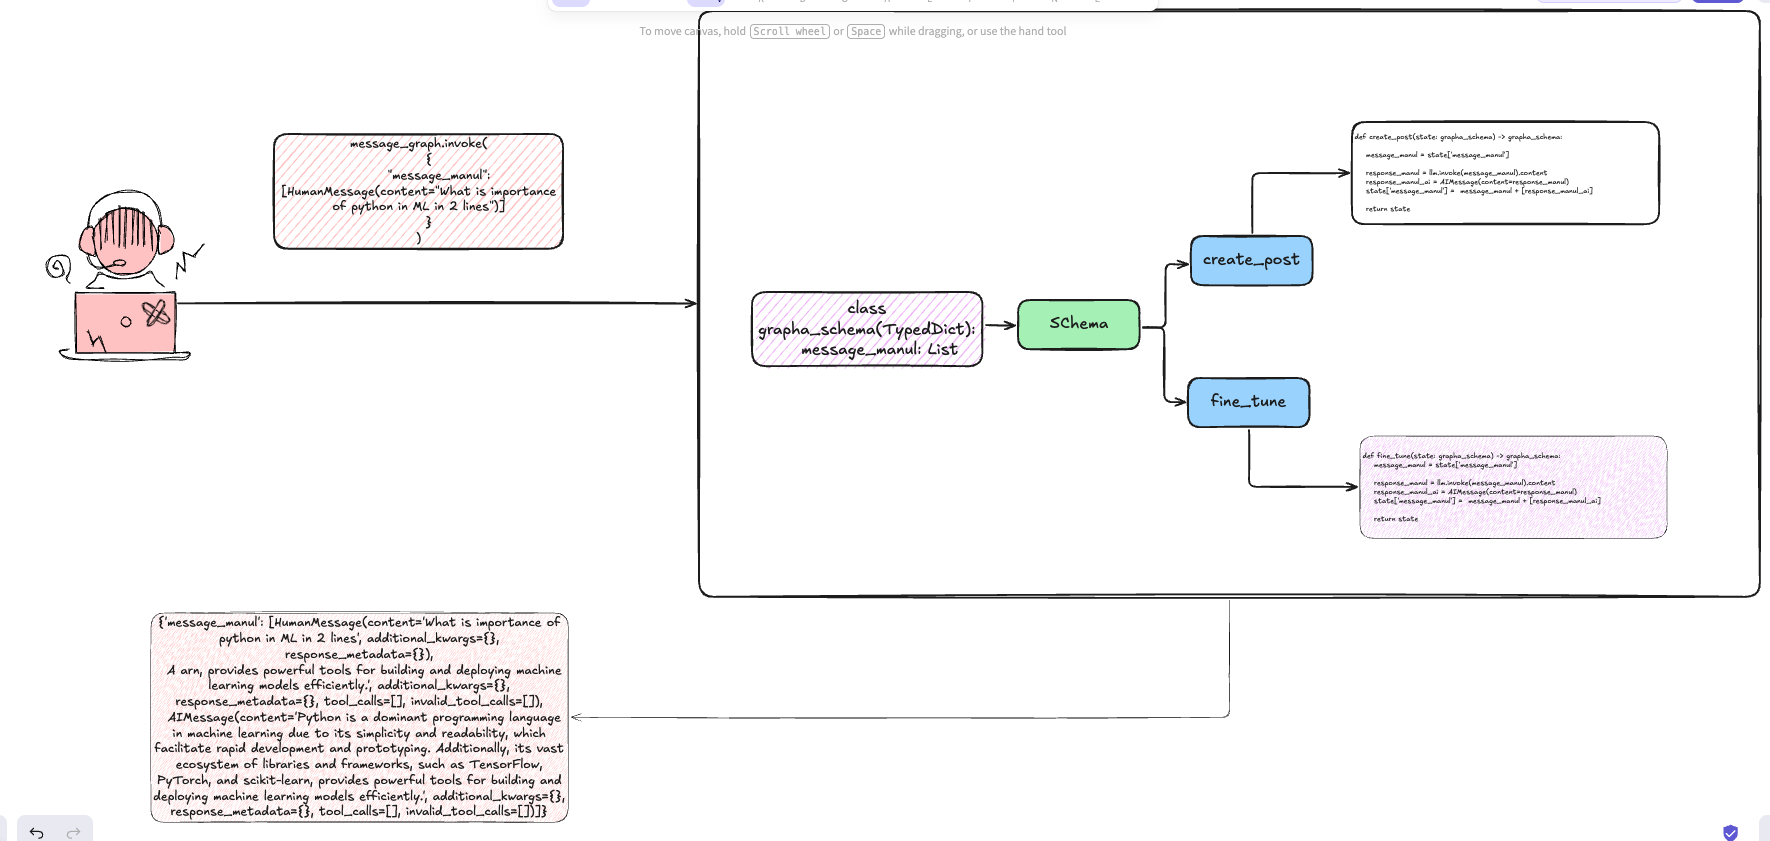